In [24]:
# Bibliotecas utilizadas

import numpy as np
from scipy.integrate import quad
import matplotlib.pyplot as plt

# Constantes utilizadas

pi = np.pi

# A equação de Bessel modificada #

As **Funções de Bessel modificadas** são as soluções da EDO de segunda ordem denominada **Equação diferencial de Bessel modificada**$,$

$$t^2\frac{d^2y}{{dt}^2} + t\frac{dy}{dt} - (t^2 - \alpha^2)y = 0\,.$$

### Função de Bessel de primeira espécie modificada ###

A **Função de Bessel de primeira espécie modificada**, $I_\alpha(t)$ é obtida a partir da **Função de Bessel de primeira espécie**, sendo dada por:

$$I_\alpha(t)=e^{-j\frac{\pi}{2}\alpha}J_\alpha(jt)=\sum\limits_{m=0}^{\infty}\frac{1}{m!\Gamma(m+\alpha+1)}\left(\frac{t}{2}\right)^{2m+\alpha}\,.$$

Como os termos da série são todos positivos, as funções de Bessel de primeira espécie modificadas são estritamente crescentes para $t>0$, não tendo oscilações, ao contrário de suas análogas não modificada. Além disso, quando $t\to\infty$, $I_\alpha(t)$ diverge para $+\infty$.

## Visualizando as funções de Bessel da primeira espécie modificadas ##

In [25]:
def fatorial(n):
    if n == 0:
        return 1
    else:
        produto = 1
        for k in range(1, n + 1, 1):
            produto *= k
        return produto

def integrando_funcao_Gamma(x, z):
    exp = np.exp(-x)
    polinomio = np.power(x, z - 1)
    return polinomio * exp

def funcao_Gamma(Z):
    if np.isscalar(Z):
        Z = np.array([Z], dtype=float)
    resultados = []
    for z in Z:
        # Polos da função Gamma (0, -1, -2, ...)
        if z <= 0 and np.isclose(z, np.round(z), rtol=0, atol=1e-12):
            resultados.append(np.inf)
            continue

        # Desloca z para o intervalo [1, 2) onde a integral é suave e bem comportada, aproveitando a propriedade \Gamma(z+1) = z\Gamma(z)
        multiplicador = 1.0
        while z < 1:
            multiplicador /= z
            z += 1
        while z >= 2:
            z -= 1
            multiplicador *= z

        def f(x):
            return integrando_funcao_Gamma(x, z)
        resultado, erro = quad(f, 0, np.inf)
        resultados.append(resultado * multiplicador)

    resultados = np.array(resultados)
    if len(resultados) == 1:
        return resultados[0]
    return resultados

def I(t, alpha, M=50):
    if not (np.isscalar(alpha)):
        raise ValueError('\u03B1 deve ser um escalar')
    soma = 0
    for m in range(0, M + 1, 1):
        denominador2 = funcao_Gamma(m + alpha + 1)
        
        # Se Gamma divergir (polo), 1/Gamma = 0; pula o termo para evitar NaN em t = 0
        if np.isinf(denominador2):
            continue

        denominador1 = fatorial(m)
        denominador = denominador1 * denominador2

        numerador = np.power(t / 2, 2 * m + alpha)

        soma += numerador / denominador

    return soma

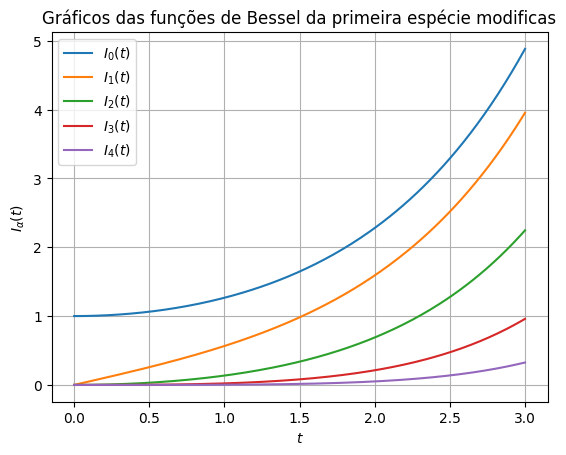

In [26]:
t0 = 0
tf = 3
M = 50

lista_alpha = [0,1,2,3,4]
t = np.linspace(t0, tf,201)

lista_I = []
for alpha in lista_alpha:
    I_alpha = I(t,alpha,M)
    lista_I.append(I_alpha)

for k in range(0, len(lista_alpha),1):
    if lista_alpha[k].is_integer():
        plt.plot(t, lista_I[k], label = r'$I_{%d}(t)$' %(lista_alpha[k]))
    else:
        plt.plot(t, lista_I[k], label = r'$I_{%.1f}(t)$' %(lista_alpha[k]))
plt.grid(True)
plt.xlabel('$t$')
plt.ylabel(r'$I_{\alpha}(t)$')
plt.title('Gráficos das funções de Bessel da primeira espécie modificas')
plt.legend(loc = 'best')
plt.show()

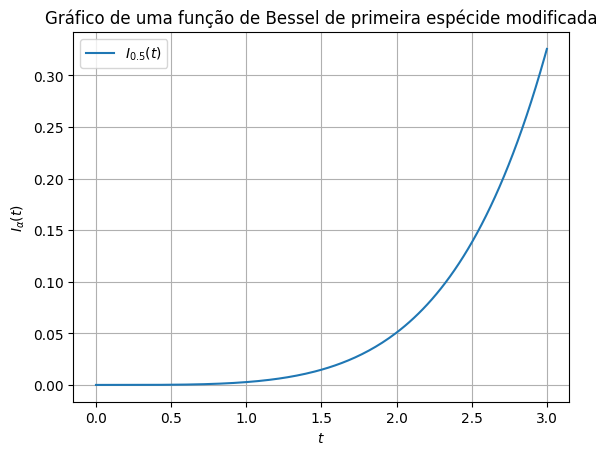

In [27]:
M = 50

alpha = 0.5
I_alpha = I(t, alpha, M)
if alpha.is_integer():
    plt.plot(t, I_alpha, label = r'$I_{%d}(t)$' %(alpha))
else:
    plt.plot(t, lista_I[k], label = r'$I_{%.1f}(t)$' %(alpha))
plt.grid(True)
plt.xlabel('$t$')
plt.ylabel(r'$I_{\alpha}(t)$')
plt.title('Gráfico de uma função de Bessel de primeira espécide modificada')
plt.legend(loc = 'best')
plt.show()

# Propriedades das funções de Bessel de primeira espécie modificadas #

A seguir, são apresentadas algumas propriedades das funções de Bessel de primeira espécie modificadas:

##### 1 - Paridade em relação ao argumento

Sendo $n$ um número inteiro, então:

$$I_n(-t)=(-1)^nI_n(t)\,.$$

##### 2 - Paridade em relação a ordem

$$I_{-n}(t)=I_n(t)\,.$$

##### 3 - Primeira identidade diferencial

$$\frac{d}{dt}\left[t^\alpha I_\alpha(t)\right]=t^\alpha I_{\alpha-1}(t)\,.$$

##### 4 - Segunda identidade diferencial

$$\frac{d}{dt}\left[t^{-\alpha}I_\alpha(t)\right]=t^{-\alpha}I_{\alpha+1}(t)\,.$$

##### 5 - Relação de recorrência algébrica

$$I_{\alpha-1}(t)-I_{\alpha+1}(t)=\frac{2\alpha}{t}I_\alpha(t)$$

##### 6 - Relação da derivada

$$I_{\alpha-1}(t)+I_{\alpha+1}(t)=2\frac{dI_\alpha(t)}{dt}\,.$$

Algumas dessas propriedades podem ser visualizadas graficamente a seguir:

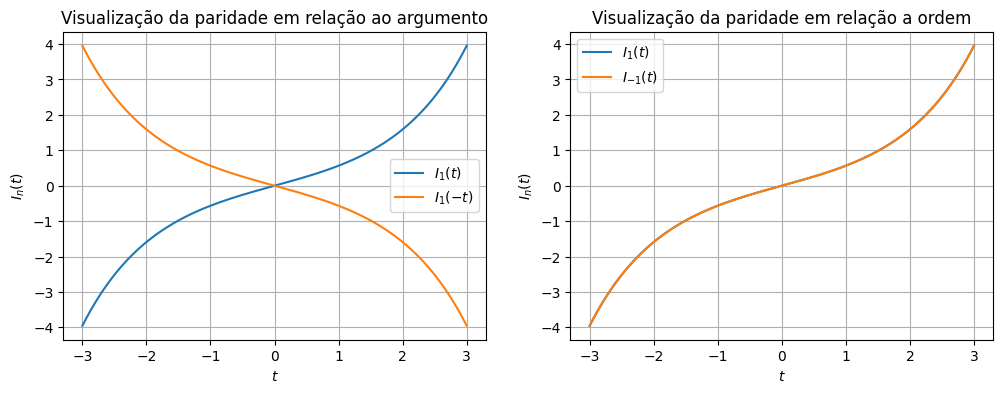

In [28]:
t0 = -3
tf = 3
M = 50

t = np.linspace(t0, tf,201)

n = 1

fig, ax = plt.subplots(1,2, figsize = (12,4))

ax[0].plot(t, I(t, n, M), label = r'$I_{%d}(t)$' %(n))
ax[0].plot(t, I(-t, n, M), label = r'$I_{%d}(-t)$' %(n))
ax[0].grid(True)
ax[0].set_xlabel('$t$')
ax[0].set_ylabel(r'$I_{n}(t)$')
ax[0].set_title('Visualização da paridade em relação ao argumento')
ax[0].legend(loc = 'best')

ax[1].plot(t, I(t, n, M), label = r'$I_{%d}(t)$' %(n))
ax[1].plot(t, I(t, -n, M), label = r'$I_{-%d}(t)$' %(n))
ax[1].grid(True)
ax[1].set_xlabel('$t$')
ax[1].set_ylabel(r'$I_{n}(t)$')
ax[1].set_title('Visualização da paridade em relação a ordem')
ax[1].legend(loc = 'best')

plt.show()